Input folder : /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/
Output folder: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots

CSV files found:
   per_epoch_k7.csv
   analysis_summary.csv
   metrics.csv
   shap_feature_details.csv
   per_subject_k7.csv

Detected:
Metrics: ['metrics.csv']
Per-subject: ['per_subject_k7.csv']
Per-epoch: ['per_epoch_k7.csv']
SHAP: ['shap_feature_details.csv']

========== METRICS ==========


,k,n_mrmr,cv_method,accuracy,precision,recall,f1,auc,kappa,source_file
0,7,50,LOOCV,0.8117,0.4598,0.5115,0.4843,0.8163,0.3695,metrics.csv



========== PER-SUBJECT RESULTS ==========


,subject_id,accuracy,precision,recall,f1,auc,kappa,source_file
0,S01,0.8354,0.4545,0.4167,0.4348,0.9104,0.3387,per_subject_k7.csv
1,S02,0.8969,0.6923,0.6000,0.6429,0.9488,0.5830,per_subject_k7.csv
2,S03,0.8235,0.0000,0.0000,0.0000,0.8619,0.0000,per_subject_k7.csv
3,S05,0.9320,0.5333,1.0000,0.6957,0.9803,0.6613,per_subject_k7.csv
4,S06,0.7985,0.4583,0.9565,0.6197,0.8668,0.5048,per_subject_k7.csv



========== PER-EPOCH RESULTS ==========


,epoch_idx,subject_id,y_true,y_pred,y_prob,source_file
0,0,S01,0,0,0.1381,per_epoch_k7.csv
1,1,S01,0,0,0.3335,per_epoch_k7.csv
2,2,S01,0,0,0.1210,per_epoch_k7.csv
3,3,S01,1,1,0.8420,per_epoch_k7.csv
4,4,S01,0,1,0.8698,per_epoch_k7.csv



========== SHAP FEATURE DETAILS ==========


,feature_index,modality,channel_number,channel_name,imf_number,feature_name,domain,shap_importance
0,1331,ET,NaN,NaN,NaN,mean_fixation_duration_ms,Eye-Tracking,0.309173
1,55,EEG,1.0,Fp1,6.0,hjorth_activity,Nonlinear Dynamics,0.228030
2,65,EEG,1.0,Fp1,7.0,hjorth_activity,Nonlinear Dynamics,0.164360
3,1338,ET,NaN,NaN,NaN,pupil_diameter_variability_px,Eye-Tracking,0.142453
4,115,EEG,2.0,Fp2,5.0,hjorth_activity,Nonlinear Dynamics,0.140040




SUMMARY

Overall metrics:


,accuracy,precision,recall,f1,auc,kappa
0,0.8117,0.4598,0.5115,0.4843,0.8163,0.3695



Number of selected SHAP features:
50


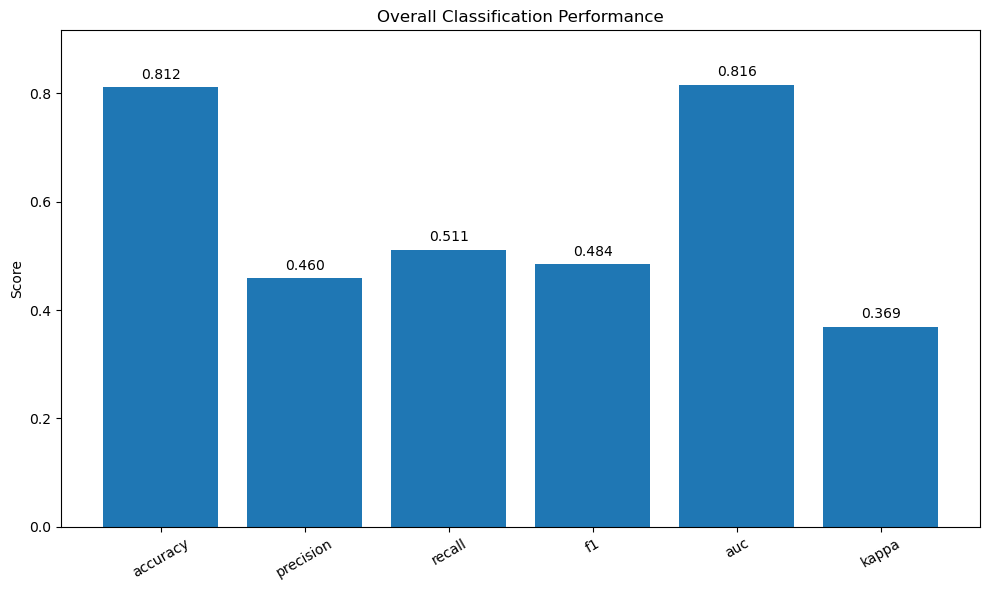

Saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/overall_performance.png


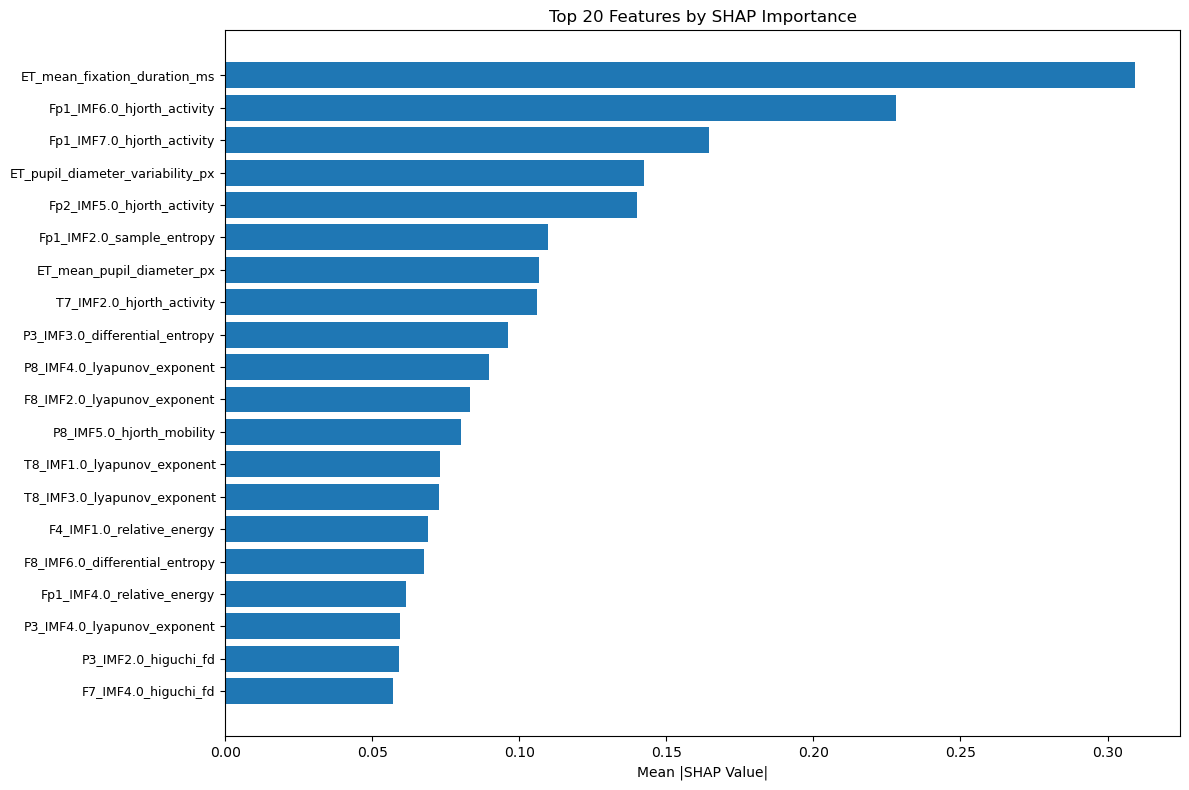

Saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/top_shap_features.png


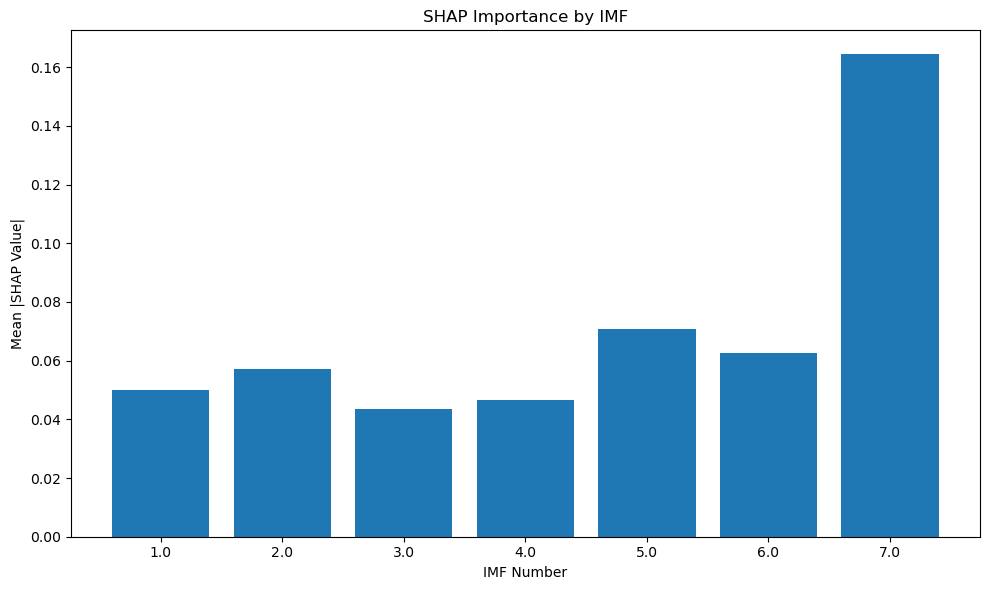

Saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/shap_by_imf.png


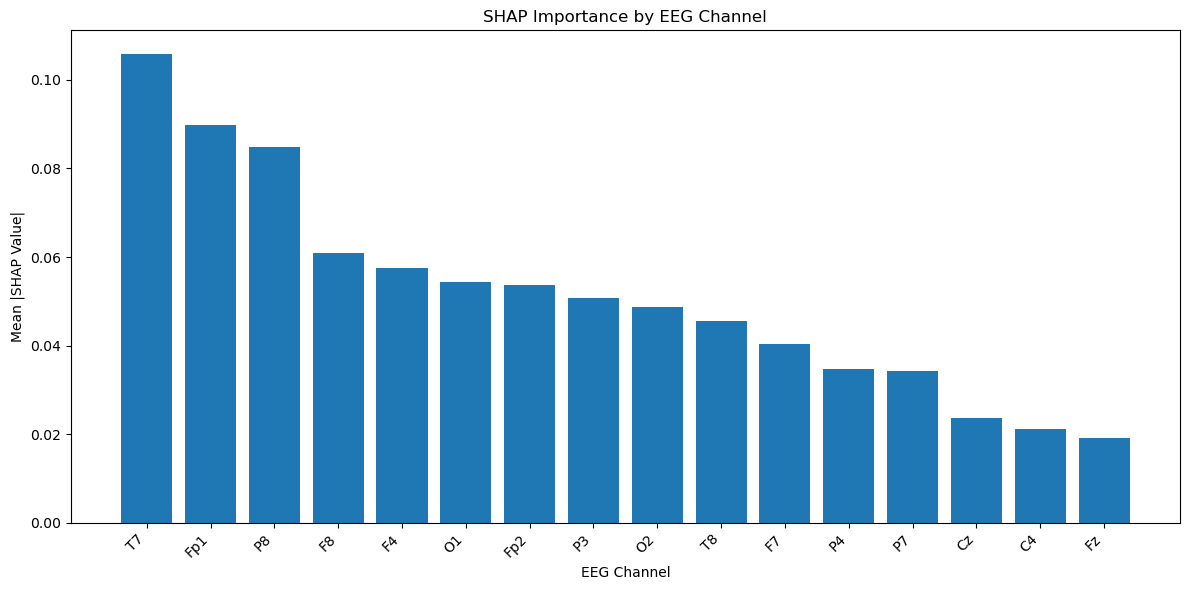

Saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/shap_by_channel.png


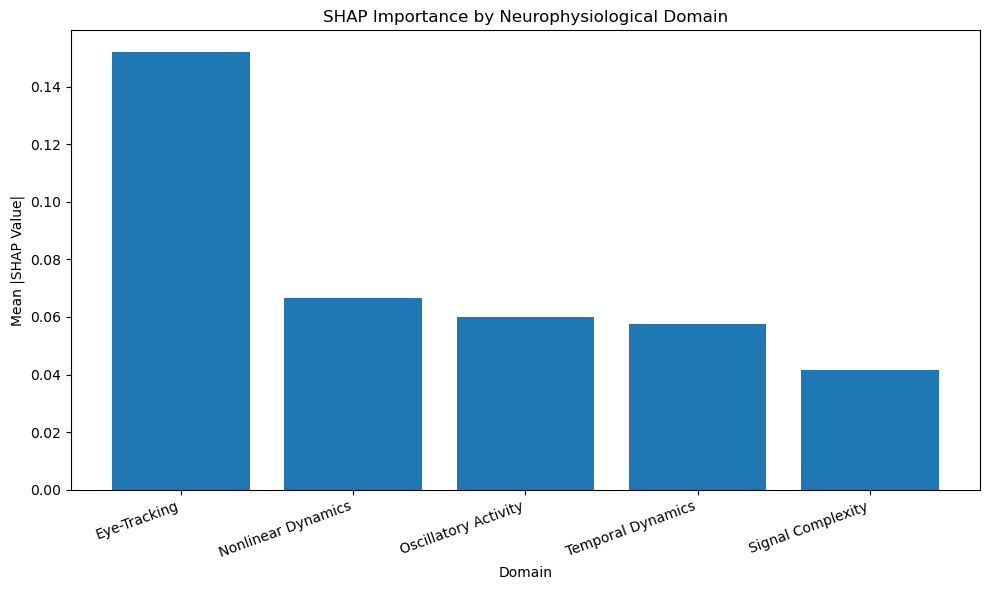

Saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/shap_by_domain.png


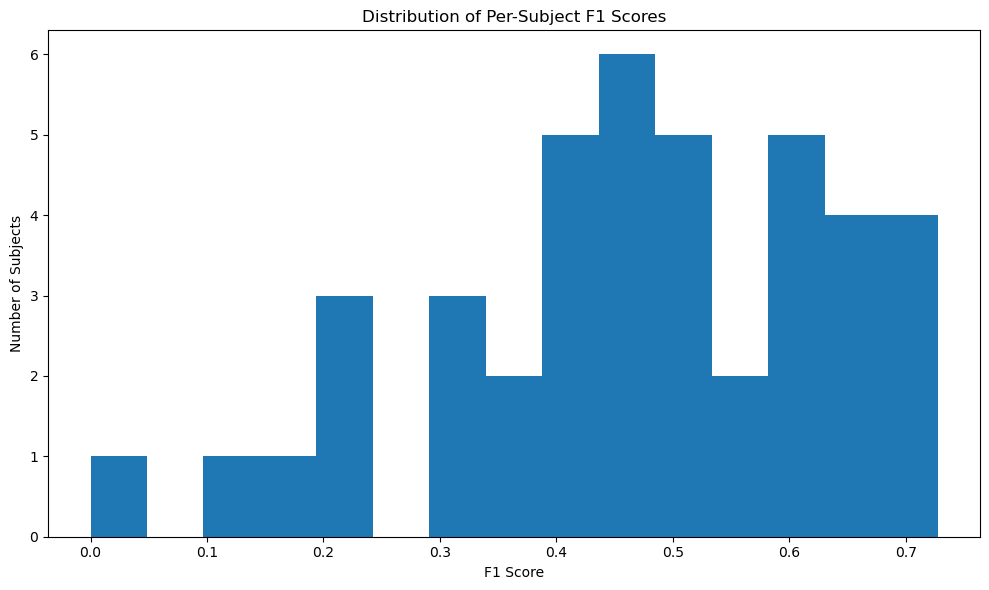

Saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/subject_f1_distribution.png


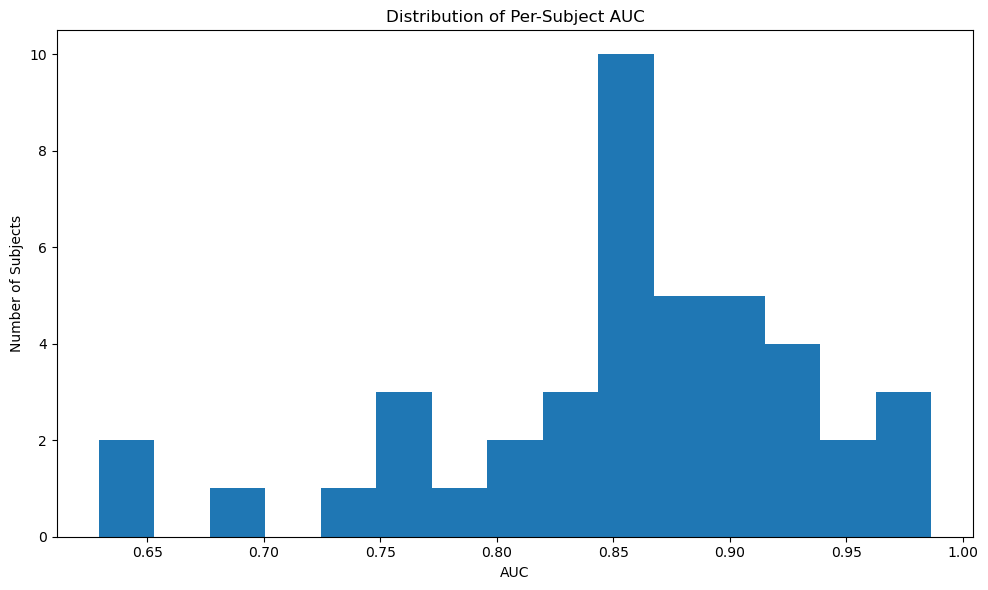

Saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/subject_auc_distribution.png


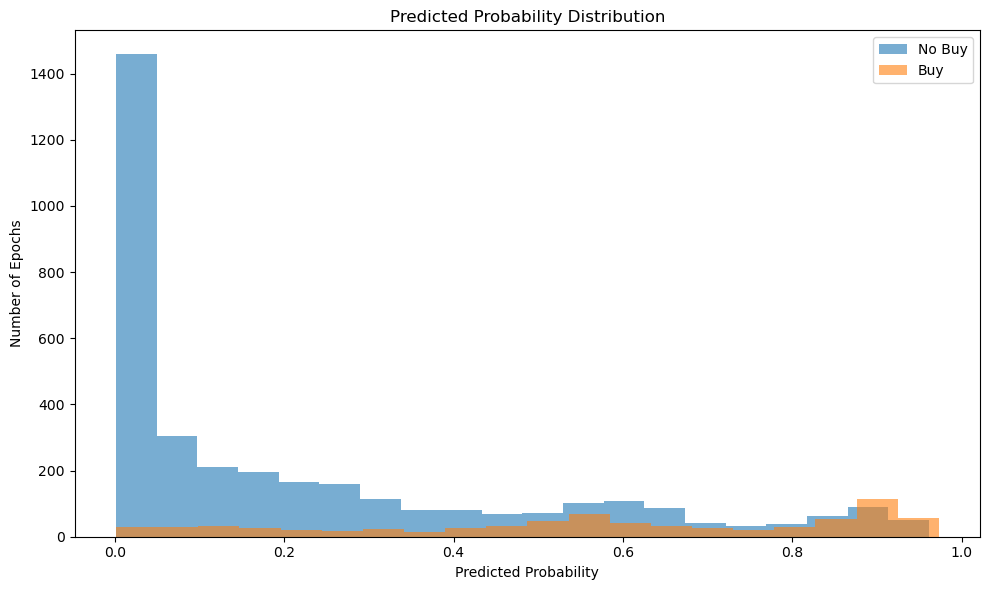

Saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/prediction_probability_distribution.png


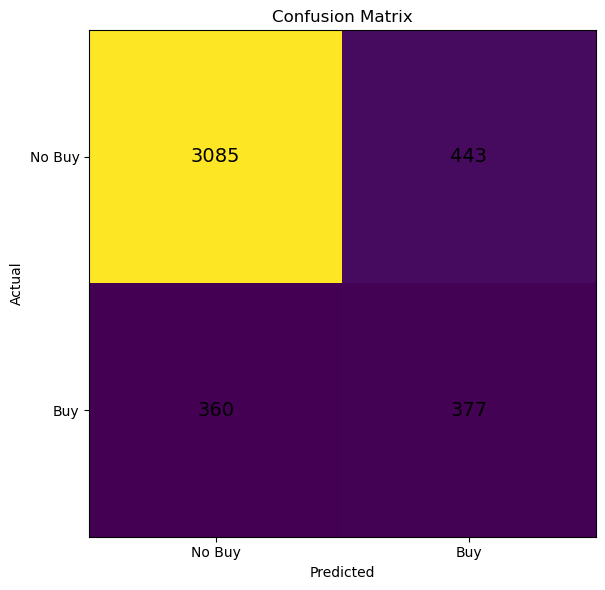

Saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/confusion_matrix.png

Summary saved: /home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots/analysis_summary.csv


ANALYSIS COMPLETE
All generated figures are located in:
/home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/analysis_plots


In [5]:
# ============================================================
# SHAP vs mRMR RESULT ANALYSIS
# JUPYTER NOTEBOOK VERSION
# No seaborn required
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SET YOUR INPUT FOLDER HERE
# ============================================================

INPUT_FOLDER = "/home/paramveer_singh/Downloads/SHAP_stack_ensemble_17th_aug/SHAP_stack_ensemble_17th_aug/results/"

# Output folder will automatically be created
OUTPUT_FOLDER = os.path.join(INPUT_FOLDER, "analysis_plots")
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

print("Input folder :", INPUT_FOLDER)
print("Output folder:", OUTPUT_FOLDER)


# ============================================================
# 2. FIND CSV FILES
# ============================================================

csv_files = [
    f for f in os.listdir(INPUT_FOLDER)
    if f.lower().endswith(".csv")
]

print("\nCSV files found:")
for f in csv_files:
    print("  ", f)

if len(csv_files) == 0:
    raise FileNotFoundError(
        "No CSV files found in the specified folder."
    )


# ============================================================
# 3. LOAD RELEVANT FILES
# ============================================================

def find_file(keyword):
    matches = [
        f for f in csv_files
        if keyword.lower() in f.lower()
    ]

    if len(matches) == 0:
        return None

    return os.path.join(INPUT_FOLDER, matches[0])


metrics_files = [
    f for f in csv_files
    if "metric" in f.lower()
]

per_subject_files = [
    f for f in csv_files
    if "per_subject" in f.lower()
]

per_epoch_files = [
    f for f in csv_files
    if "per_epoch" in f.lower()
]

shap_files = [
    f for f in csv_files
    if "shap" in f.lower()
]

print("\nDetected:")
print("Metrics:", metrics_files)
print("Per-subject:", per_subject_files)
print("Per-epoch:", per_epoch_files)
print("SHAP:", shap_files)


# ============================================================
# 4. LOAD METRICS
# ============================================================

metrics_data = []

for f in metrics_files:
    path = os.path.join(INPUT_FOLDER, f)

    try:
        df = pd.read_csv(path)
        df["source_file"] = f
        metrics_data.append(df)
    except Exception as e:
        print("Could not read:", f, "->", e)

if metrics_data:
    metrics_df = pd.concat(metrics_data, ignore_index=True)

    print("\n========== METRICS ==========")
    display(metrics_df)

else:
    metrics_df = pd.DataFrame()
    print("\nNo metrics CSV detected.")


# ============================================================
# 5. LOAD PER-SUBJECT RESULTS
# ============================================================

subject_data = []

for f in per_subject_files:
    path = os.path.join(INPUT_FOLDER, f)

    try:
        df = pd.read_csv(path)
        df["source_file"] = f
        subject_data.append(df)
    except Exception as e:
        print("Could not read:", f, "->", e)

if subject_data:
    subject_df = pd.concat(subject_data, ignore_index=True)

    print("\n========== PER-SUBJECT RESULTS ==========")
    display(subject_df.head())

else:
    subject_df = pd.DataFrame()
    print("\nNo per-subject CSV detected.")


# ============================================================
# 6. LOAD PER-EPOCH RESULTS
# ============================================================

epoch_data = []

for f in per_epoch_files:
    path = os.path.join(INPUT_FOLDER, f)

    try:
        df = pd.read_csv(path)
        df["source_file"] = f
        epoch_data.append(df)
    except Exception as e:
        print("Could not read:", f, "->", e)

if epoch_data:
    epoch_df = pd.concat(epoch_data, ignore_index=True)

    print("\n========== PER-EPOCH RESULTS ==========")
    display(epoch_df.head())

else:
    epoch_df = pd.DataFrame()
    print("\nNo per-epoch CSV detected.")


# ============================================================
# 7. LOAD SHAP FEATURE DETAILS
# ============================================================

shap_feature_files = [
    f for f in csv_files
    if "shap_feature_details" in f.lower()
]

if shap_feature_files:

    shap_path = os.path.join(
        INPUT_FOLDER,
        shap_feature_files[0]
    )

    shap_df = pd.read_csv(shap_path)

    print("\n========== SHAP FEATURE DETAILS ==========")
    display(shap_df.head())

else:

    shap_df = pd.DataFrame()

    print(
        "\nNo shap_feature_details.csv detected."
    )


# ============================================================
# 8. BASIC SUMMARY
# ============================================================

print("\n")
print("=" * 60)
print("SUMMARY")
print("=" * 60)

if not metrics_df.empty:

    print("\nOverall metrics:")

    metric_columns = [
        "accuracy",
        "precision",
        "recall",
        "f1",
        "auc",
        "kappa"
    ]

    available = [
        c for c in metric_columns
        if c in metrics_df.columns
    ]

    display(metrics_df[available])


if not shap_df.empty:

    print("\nNumber of selected SHAP features:")

    print(len(shap_df))


# ============================================================
# 9. PLOT OVERALL PERFORMANCE
# ============================================================

if not metrics_df.empty:

    metric_columns = [
        "accuracy",
        "precision",
        "recall",
        "f1",
        "auc",
        "kappa"
    ]

    available = [
        c for c in metric_columns
        if c in metrics_df.columns
    ]

    if available:

        values = [
            float(metrics_df[c].iloc[0])
            for c in available
        ]

        fig, ax = plt.subplots(figsize=(10, 6))

        ax.bar(available, values)

        ax.set_ylim(
            min(0, min(values) - 0.05),
            min(1.0, max(values) + 0.10)
        )

        ax.set_ylabel("Score")
        ax.set_title("Overall Classification Performance")

        for i, v in enumerate(values):
            ax.text(
                i,
                v + 0.015,
                f"{v:.3f}",
                ha="center",
                fontsize=10
            )

        plt.xticks(rotation=30)
        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "overall_performance.png"
        )

        fig.savefig(path, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 10. SHAP FEATURE IMPORTANCE
# ============================================================

if not shap_df.empty:

    if "shap_importance" in shap_df.columns:

        top_n = min(20, len(shap_df))

        top_features = (
            shap_df
            .sort_values(
                "shap_importance",
                ascending=False
            )
            .head(top_n)
            .iloc[::-1]
        )

        # Create readable labels
        labels = []

        for _, row in top_features.iterrows():

            if str(row.get("modality", "")).upper() == "EEG":

                label = (
                    f"{row.get('channel_name', '')}_"
                    f"IMF{row.get('imf_number', '')}_"
                    f"{row.get('feature_name', '')}"
                )

            else:

                label = (
                    f"ET_"
                    f"{row.get('feature_name', '')}"
                )

            labels.append(label)

        values = top_features[
            "shap_importance"
        ].values

        fig, ax = plt.subplots(figsize=(12, 8))

        ax.barh(
            range(len(labels)),
            values
        )

        ax.set_yticks(range(len(labels)))
        ax.set_yticklabels(
            labels,
            fontsize=9
        )

        ax.set_xlabel("Mean |SHAP Value|")

        ax.set_title(
            f"Top {top_n} Features by SHAP Importance"
        )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "top_shap_features.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 11. SHAP IMPORTANCE BY IMF
# ============================================================

if not shap_df.empty:

    required = {
        "imf_number",
        "shap_importance"
    }

    if required.issubset(shap_df.columns):

        imf_df = shap_df.dropna(
            subset=["imf_number"]
        ).copy()

        if not imf_df.empty:

            imf_summary = (
                imf_df
                .groupby("imf_number")
                ["shap_importance"]
                .mean()
                .sort_index()
            )

            fig, ax = plt.subplots(
                figsize=(10, 6)
            )

            ax.bar(
                imf_summary.index.astype(str),
                imf_summary.values
            )

            ax.set_xlabel("IMF Number")
            ax.set_ylabel(
                "Mean |SHAP Value|"
            )

            ax.set_title(
                "SHAP Importance by IMF"
            )

            plt.tight_layout()

            path = os.path.join(
                OUTPUT_FOLDER,
                "shap_by_imf.png"
            )

            fig.savefig(
                path,
                dpi=300,
                bbox_inches="tight"
            )

            plt.show()
            plt.close()

            print("Saved:", path)


# ============================================================
# 12. SHAP IMPORTANCE BY EEG CHANNEL
# ============================================================

if not shap_df.empty:

    required = {
        "channel_name",
        "shap_importance"
    }

    if required.issubset(shap_df.columns):

        channel_df = shap_df.dropna(
            subset=["channel_name"]
        ).copy()

        if not channel_df.empty:

            channel_summary = (
                channel_df
                .groupby("channel_name")
                ["shap_importance"]
                .mean()
                .sort_values(
                    ascending=False
                )
            )

            fig, ax = plt.subplots(
                figsize=(12, 6)
            )

            ax.bar(
                channel_summary.index.astype(str),
                channel_summary.values
            )

            ax.set_xlabel("EEG Channel")
            ax.set_ylabel(
                "Mean |SHAP Value|"
            )

            ax.set_title(
                "SHAP Importance by EEG Channel"
            )

            plt.xticks(
                rotation=45,
                ha="right"
            )

            plt.tight_layout()

            path = os.path.join(
                OUTPUT_FOLDER,
                "shap_by_channel.png"
            )

            fig.savefig(
                path,
                dpi=300,
                bbox_inches="tight"
            )

            plt.show()
            plt.close()

            print("Saved:", path)


# ============================================================
# 13. SHAP IMPORTANCE BY DOMAIN
# ============================================================

if not shap_df.empty:

    if {
        "domain",
        "shap_importance"
    }.issubset(shap_df.columns):

        domain_summary = (
            shap_df
            .groupby("domain")
            ["shap_importance"]
            .mean()
            .sort_values(
                ascending=False
            )
        )

        fig, ax = plt.subplots(
            figsize=(10, 6)
        )

        ax.bar(
            domain_summary.index,
            domain_summary.values
        )

        ax.set_xlabel("Domain")
        ax.set_ylabel(
            "Mean |SHAP Value|"
        )

        ax.set_title(
            "SHAP Importance by Neurophysiological Domain"
        )

        plt.xticks(
            rotation=20,
            ha="right"
        )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "shap_by_domain.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 14. PER-SUBJECT F1 DISTRIBUTION
# ============================================================

if not subject_df.empty:

    if "f1" in subject_df.columns:

        values = pd.to_numeric(
            subject_df["f1"],
            errors="coerce"
        ).dropna()

        fig, ax = plt.subplots(
            figsize=(10, 6)
        )

        ax.hist(
            values,
            bins=15
        )

        ax.set_xlabel("F1 Score")
        ax.set_ylabel("Number of Subjects")

        ax.set_title(
            "Distribution of Per-Subject F1 Scores"
        )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "subject_f1_distribution.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 15. PER-SUBJECT AUC DISTRIBUTION
# ============================================================

if not subject_df.empty:

    if "auc" in subject_df.columns:

        values = pd.to_numeric(
            subject_df["auc"],
            errors="coerce"
        ).dropna()

        fig, ax = plt.subplots(
            figsize=(10, 6)
        )

        ax.hist(
            values,
            bins=15
        )

        ax.set_xlabel("AUC")
        ax.set_ylabel("Number of Subjects")

        ax.set_title(
            "Distribution of Per-Subject AUC"
        )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "subject_auc_distribution.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 16. PREDICTION PROBABILITY DISTRIBUTION
# ============================================================

if not epoch_df.empty:

    if {
        "y_true",
        "y_prob"
    }.issubset(epoch_df.columns):

        fig, ax = plt.subplots(
            figsize=(10, 6)
        )

        buy = epoch_df[
            epoch_df["y_true"] == 1
        ]["y_prob"]

        no_buy = epoch_df[
            epoch_df["y_true"] == 0
        ]["y_prob"]

        ax.hist(
            no_buy,
            bins=20,
            alpha=0.6,
            label="No Buy"
        )

        ax.hist(
            buy,
            bins=20,
            alpha=0.6,
            label="Buy"
        )

        ax.set_xlabel(
            "Predicted Probability"
        )

        ax.set_ylabel(
            "Number of Epochs"
        )

        ax.set_title(
            "Predicted Probability Distribution"
        )

        ax.legend()

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "prediction_probability_distribution.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 17. CONFUSION MATRIX
# ============================================================

if not epoch_df.empty:

    if {
        "y_true",
        "y_pred"
    }.issubset(epoch_df.columns):

        yt = epoch_df["y_true"]
        yp = epoch_df["y_pred"]

        cm = pd.crosstab(
            yt,
            yp
        )

        # Ensure 0/1 rows and columns exist
        cm = cm.reindex(
            index=[0, 1],
            columns=[0, 1],
            fill_value=0
        )

        fig, ax = plt.subplots(
            figsize=(7, 6)
        )

        ax.imshow(cm.values)

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        ax.set_xticklabels(
            ["No Buy", "Buy"]
        )

        ax.set_yticklabels(
            ["No Buy", "Buy"]
        )

        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

        ax.set_title(
            "Confusion Matrix"
        )

        for i in range(2):
            for j in range(2):

                ax.text(
                    j,
                    i,
                    str(cm.iloc[i, j]),
                    ha="center",
                    va="center",
                    fontsize=14
                )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "confusion_matrix.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 18. SAVE SUMMARY TABLE
# ============================================================

summary_path = os.path.join(
    OUTPUT_FOLDER,
    "analysis_summary.csv"
)

if not metrics_df.empty:

    metrics_df.to_csv(
        summary_path,
        index=False
    )

    print(
        "\nSummary saved:",
        summary_path
    )


# ============================================================
# 19. FINAL MESSAGE
# ============================================================

print("\n")
print("=" * 60)
print("ANALYSIS COMPLETE")
print("=" * 60)
print(
    "All generated figures are located in:"
)
print(OUTPUT_FOLDER)
print("=" * 60)

Input folder : /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/
Output folder: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots

CSV files found:
   per_epoch_k7.csv
   analysis_summary.csv
   metrics.csv
   shap_feature_details.csv
   per_subject_k7.csv

Detected:
Metrics: ['metrics.csv']
Per-subject: ['per_subject_k7.csv']
Per-epoch: ['per_epoch_k7.csv']
SHAP: ['shap_feature_details.csv']

========== METRICS ==========


,k,n_mrmr,cv_method,accuracy,precision,recall,f1,auc,kappa,source_file
0,7,80,LOOCV,0.7899,0.4178,0.5482,0.4742,0.8049,0.3459,metrics.csv



========== PER-SUBJECT RESULTS ==========


,subject_id,accuracy,precision,recall,f1,auc,kappa,source_file
0,S01,0.9114,0.6923,0.7500,0.7200,0.9341,0.6675,per_subject_k7.csv
1,S02,0.8763,0.5882,0.6667,0.6250,0.9537,0.5513,per_subject_k7.csv
2,S03,0.8706,1.0000,0.2667,0.4211,0.8276,0.3746,per_subject_k7.csv
3,S05,0.9223,0.5000,1.0000,0.6667,0.9724,0.6282,per_subject_k7.csv
4,S06,0.7313,0.3818,0.9130,0.5385,0.8457,0.3911,per_subject_k7.csv



========== PER-EPOCH RESULTS ==========


,epoch_idx,subject_id,y_true,y_pred,y_prob,source_file
0,0,S01,0,0,0.0748,per_epoch_k7.csv
1,1,S01,0,0,0.1629,per_epoch_k7.csv
2,2,S01,0,0,0.2203,per_epoch_k7.csv
3,3,S01,1,1,0.9096,per_epoch_k7.csv
4,4,S01,0,0,0.5557,per_epoch_k7.csv



========== SHAP FEATURE DETAILS ==========


,feature_index,modality,channel_number,channel_name,imf_number,feature_name,domain,shap_importance
0,1015,EEG,15.0,P7,4.0,hjorth_activity,Nonlinear Dynamics,0.357577
1,1332,ET,NaN,NaN,NaN,total_fixation_duration_ms,Eye-Tracking,0.289645
2,825,EEG,12.0,F8,6.0,hjorth_activity,Nonlinear Dynamics,0.149069
3,1338,ET,NaN,NaN,NaN,pupil_diameter_variability_px,Eye-Tracking,0.139979
4,1337,ET,NaN,NaN,NaN,mean_pupil_diameter_px,Eye-Tracking,0.129391




SUMMARY

Overall metrics:


,accuracy,precision,recall,f1,auc,kappa
0,0.7899,0.4178,0.5482,0.4742,0.8049,0.3459



Number of selected SHAP features:
80


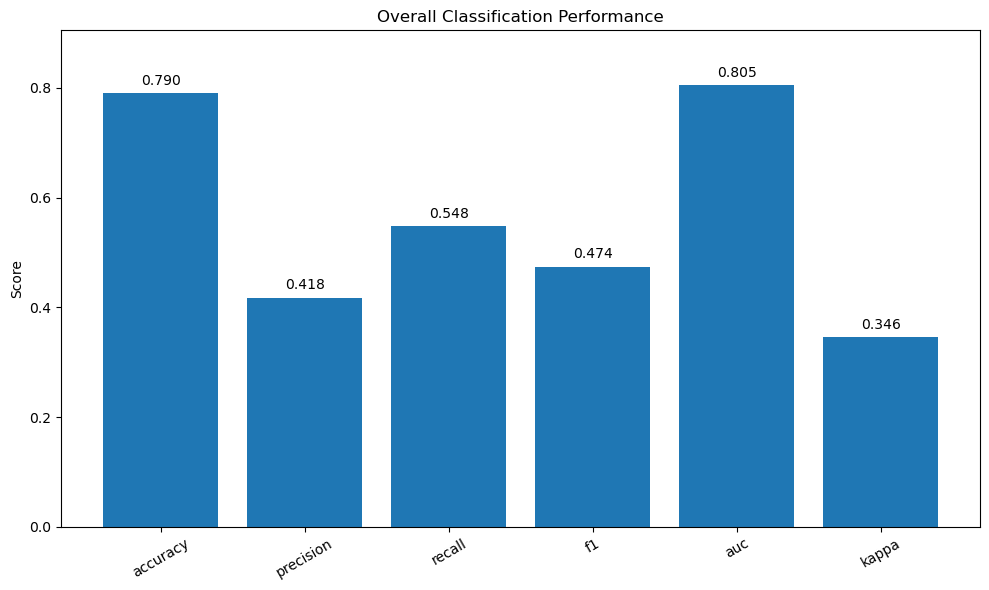

Saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/overall_performance.png


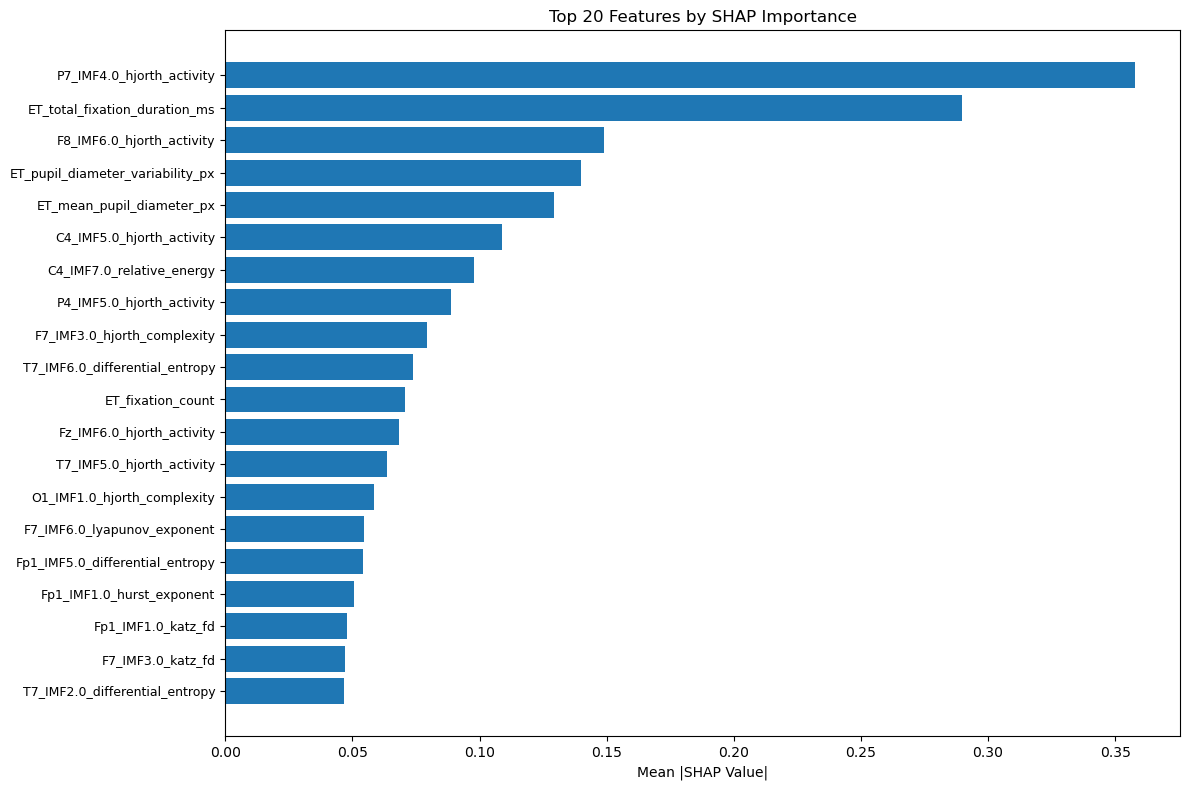

Saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/top_shap_features.png


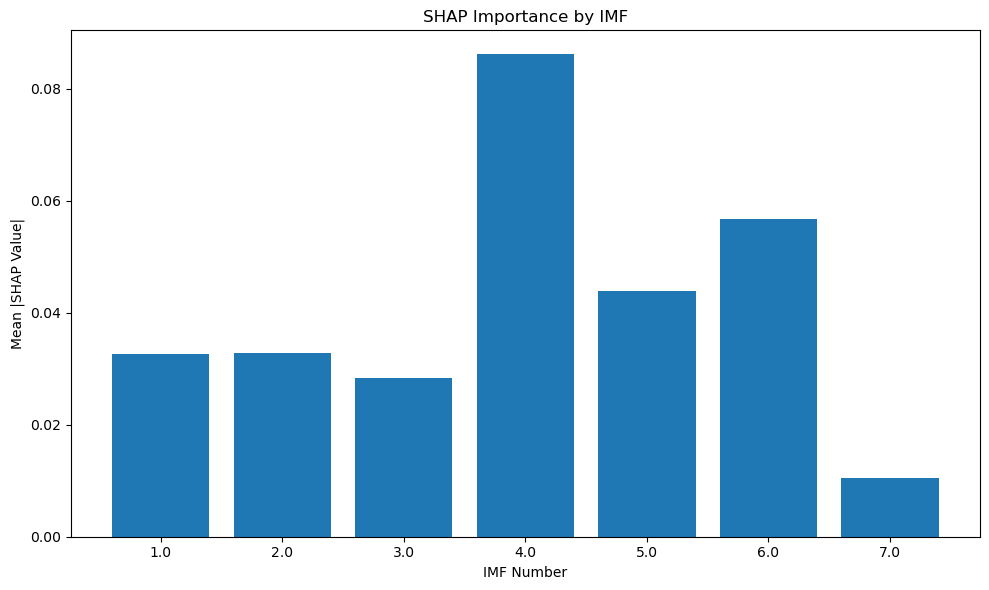

Saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/shap_by_imf.png


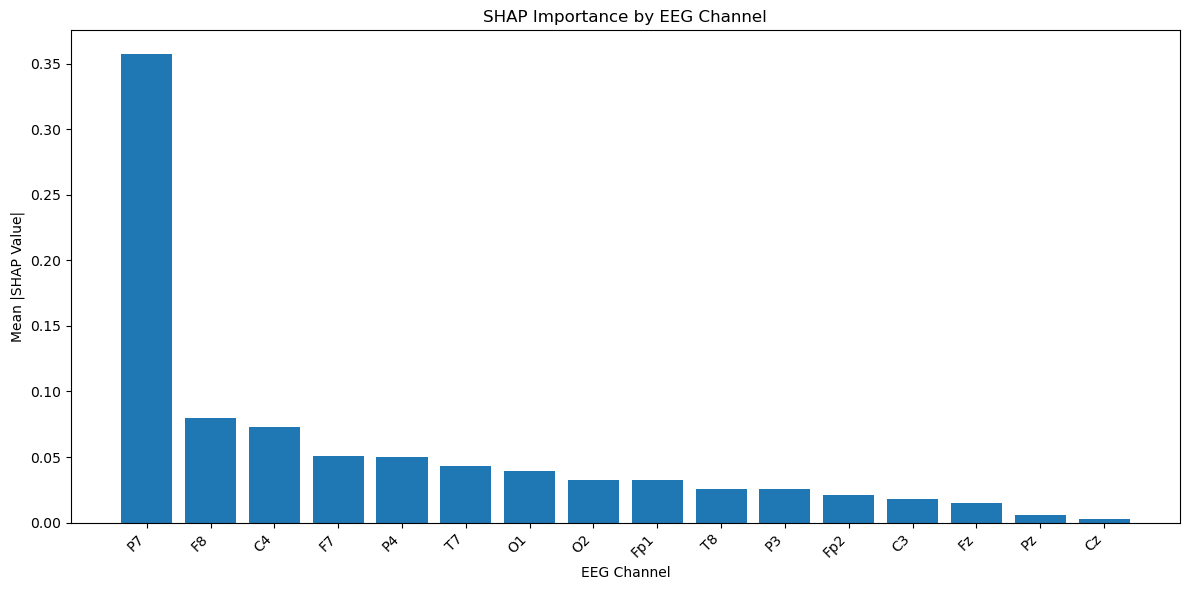

Saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/shap_by_channel.png


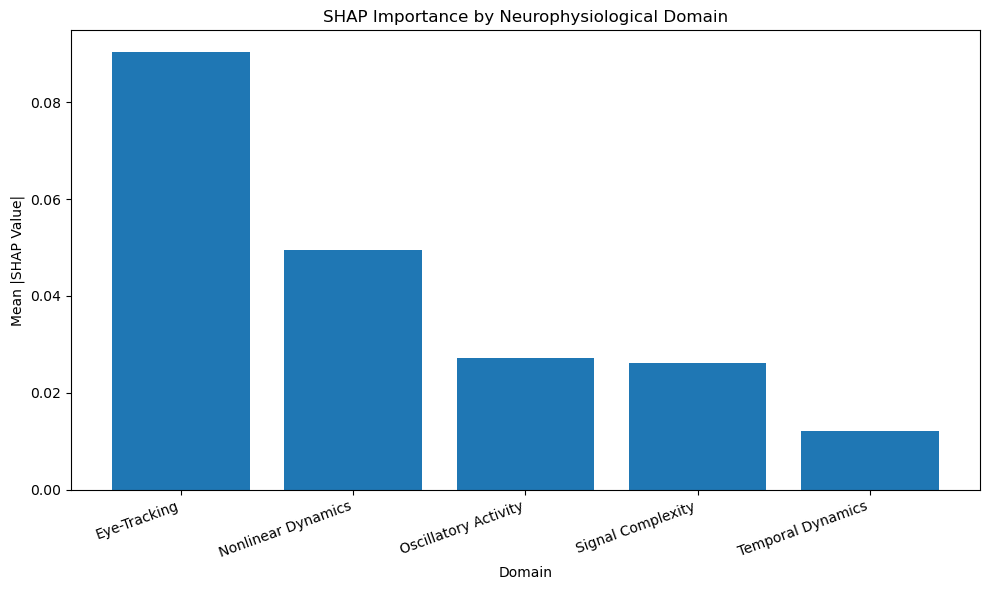

Saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/shap_by_domain.png


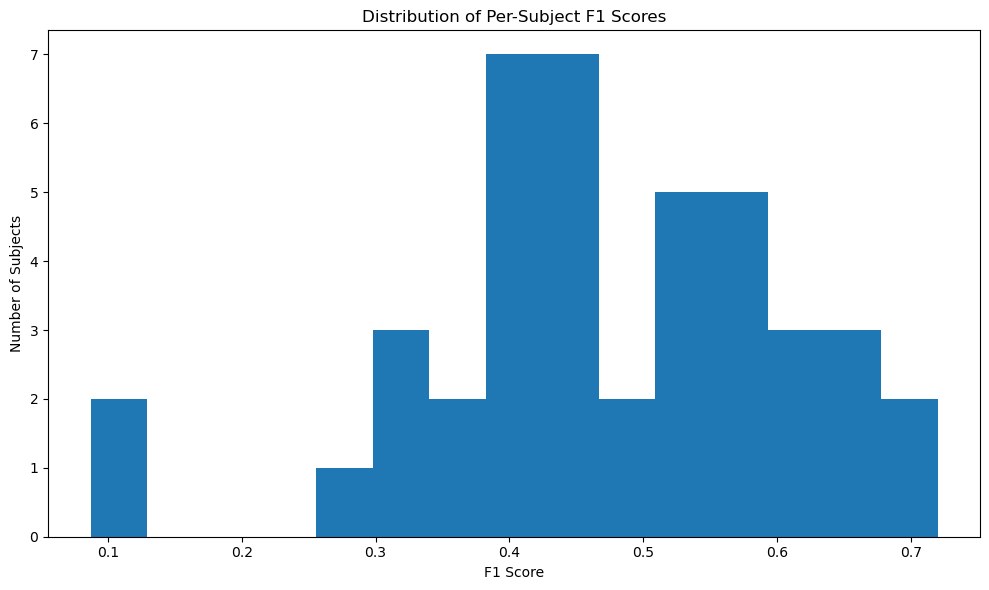

Saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/subject_f1_distribution.png


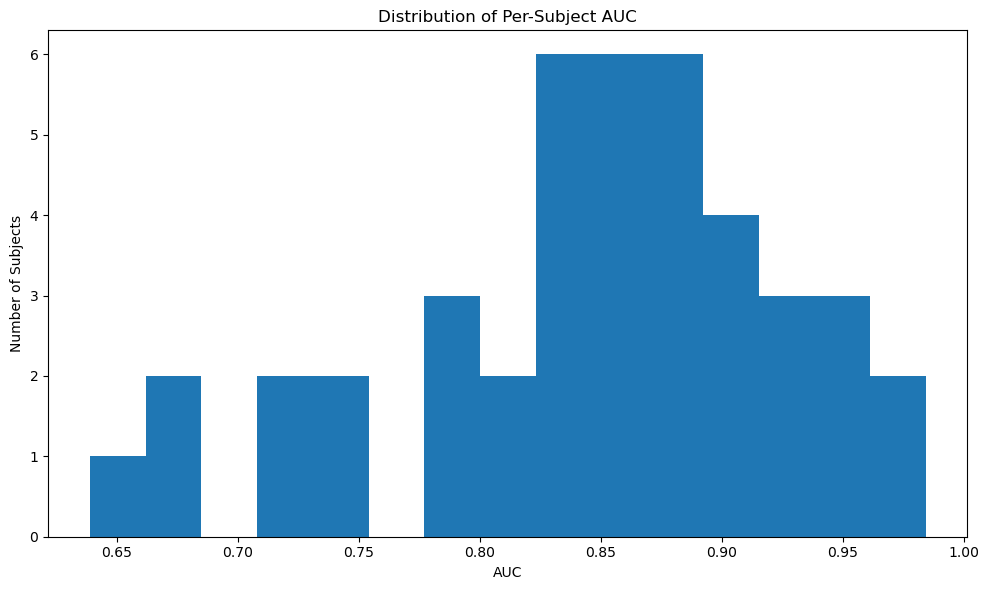

Saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/subject_auc_distribution.png


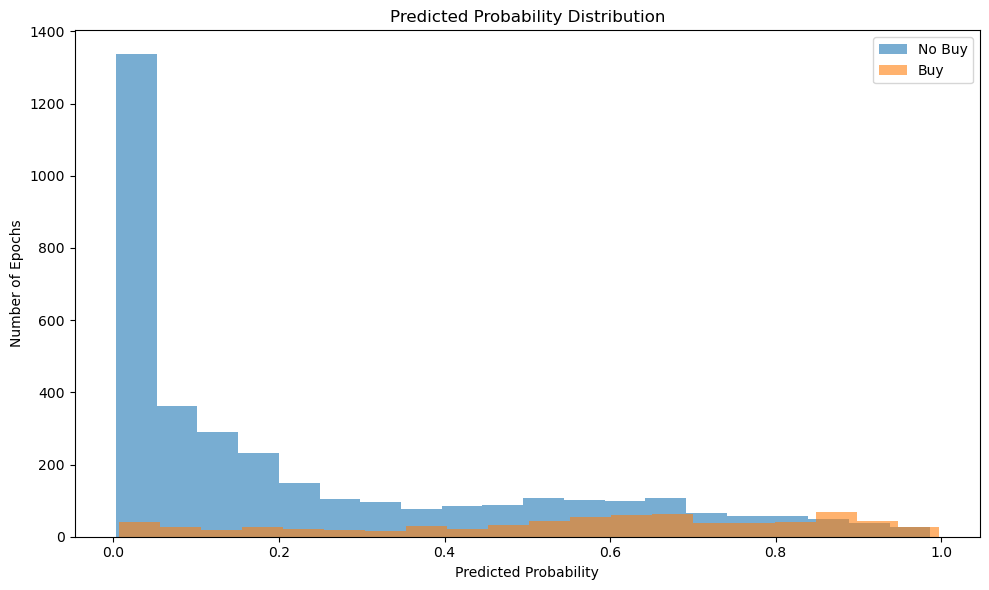

Saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/prediction_probability_distribution.png


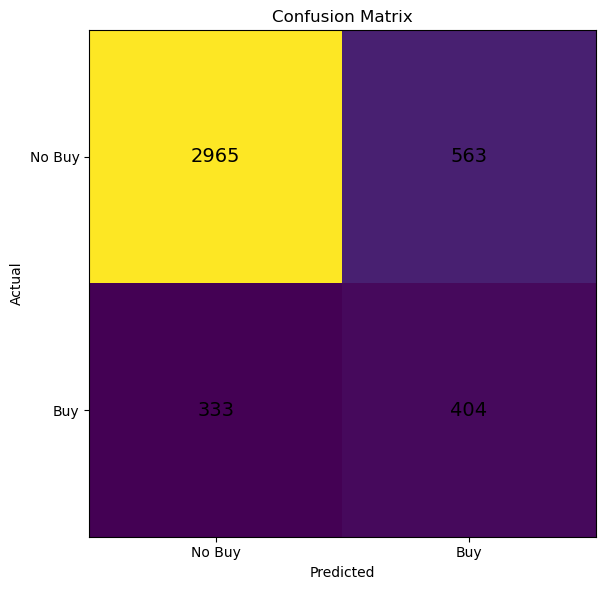

Saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/confusion_matrix.png

Summary saved: /home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots/analysis_summary.csv


ANALYSIS COMPLETE
All generated figures are located in:
/home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/analysis_plots


In [6]:
# ============================================================
# SHAP vs mRMR RESULT ANALYSIS
# JUPYTER NOTEBOOK VERSION
# No seaborn required
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SET YOUR INPUT FOLDER HERE
# ============================================================

INPUT_FOLDER = "/home/paramveer_singh/Downloads/mRMR_stack_ensemble_17th_aug/mRMR_stack_ensemble_17th_aug/results/"

# Output folder will automatically be created
OUTPUT_FOLDER = os.path.join(INPUT_FOLDER, "analysis_plots")
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

print("Input folder :", INPUT_FOLDER)
print("Output folder:", OUTPUT_FOLDER)


# ============================================================
# 2. FIND CSV FILES
# ============================================================

csv_files = [
    f for f in os.listdir(INPUT_FOLDER)
    if f.lower().endswith(".csv")
]

print("\nCSV files found:")
for f in csv_files:
    print("  ", f)

if len(csv_files) == 0:
    raise FileNotFoundError(
        "No CSV files found in the specified folder."
    )


# ============================================================
# 3. LOAD RELEVANT FILES
# ============================================================

def find_file(keyword):
    matches = [
        f for f in csv_files
        if keyword.lower() in f.lower()
    ]

    if len(matches) == 0:
        return None

    return os.path.join(INPUT_FOLDER, matches[0])


metrics_files = [
    f for f in csv_files
    if "metric" in f.lower()
]

per_subject_files = [
    f for f in csv_files
    if "per_subject" in f.lower()
]

per_epoch_files = [
    f for f in csv_files
    if "per_epoch" in f.lower()
]

shap_files = [
    f for f in csv_files
    if "shap" in f.lower()
]

print("\nDetected:")
print("Metrics:", metrics_files)
print("Per-subject:", per_subject_files)
print("Per-epoch:", per_epoch_files)
print("SHAP:", shap_files)


# ============================================================
# 4. LOAD METRICS
# ============================================================

metrics_data = []

for f in metrics_files:
    path = os.path.join(INPUT_FOLDER, f)

    try:
        df = pd.read_csv(path)
        df["source_file"] = f
        metrics_data.append(df)
    except Exception as e:
        print("Could not read:", f, "->", e)

if metrics_data:
    metrics_df = pd.concat(metrics_data, ignore_index=True)

    print("\n========== METRICS ==========")
    display(metrics_df)

else:
    metrics_df = pd.DataFrame()
    print("\nNo metrics CSV detected.")


# ============================================================
# 5. LOAD PER-SUBJECT RESULTS
# ============================================================

subject_data = []

for f in per_subject_files:
    path = os.path.join(INPUT_FOLDER, f)

    try:
        df = pd.read_csv(path)
        df["source_file"] = f
        subject_data.append(df)
    except Exception as e:
        print("Could not read:", f, "->", e)

if subject_data:
    subject_df = pd.concat(subject_data, ignore_index=True)

    print("\n========== PER-SUBJECT RESULTS ==========")
    display(subject_df.head())

else:
    subject_df = pd.DataFrame()
    print("\nNo per-subject CSV detected.")


# ============================================================
# 6. LOAD PER-EPOCH RESULTS
# ============================================================

epoch_data = []

for f in per_epoch_files:
    path = os.path.join(INPUT_FOLDER, f)

    try:
        df = pd.read_csv(path)
        df["source_file"] = f
        epoch_data.append(df)
    except Exception as e:
        print("Could not read:", f, "->", e)

if epoch_data:
    epoch_df = pd.concat(epoch_data, ignore_index=True)

    print("\n========== PER-EPOCH RESULTS ==========")
    display(epoch_df.head())

else:
    epoch_df = pd.DataFrame()
    print("\nNo per-epoch CSV detected.")


# ============================================================
# 7. LOAD SHAP FEATURE DETAILS
# ============================================================

shap_feature_files = [
    f for f in csv_files
    if "shap_feature_details" in f.lower()
]

if shap_feature_files:

    shap_path = os.path.join(
        INPUT_FOLDER,
        shap_feature_files[0]
    )

    shap_df = pd.read_csv(shap_path)

    print("\n========== SHAP FEATURE DETAILS ==========")
    display(shap_df.head())

else:

    shap_df = pd.DataFrame()

    print(
        "\nNo shap_feature_details.csv detected."
    )


# ============================================================
# 8. BASIC SUMMARY
# ============================================================

print("\n")
print("=" * 60)
print("SUMMARY")
print("=" * 60)

if not metrics_df.empty:

    print("\nOverall metrics:")

    metric_columns = [
        "accuracy",
        "precision",
        "recall",
        "f1",
        "auc",
        "kappa"
    ]

    available = [
        c for c in metric_columns
        if c in metrics_df.columns
    ]

    display(metrics_df[available])


if not shap_df.empty:

    print("\nNumber of selected SHAP features:")

    print(len(shap_df))


# ============================================================
# 9. PLOT OVERALL PERFORMANCE
# ============================================================

if not metrics_df.empty:

    metric_columns = [
        "accuracy",
        "precision",
        "recall",
        "f1",
        "auc",
        "kappa"
    ]

    available = [
        c for c in metric_columns
        if c in metrics_df.columns
    ]

    if available:

        values = [
            float(metrics_df[c].iloc[0])
            for c in available
        ]

        fig, ax = plt.subplots(figsize=(10, 6))

        ax.bar(available, values)

        ax.set_ylim(
            min(0, min(values) - 0.05),
            min(1.0, max(values) + 0.10)
        )

        ax.set_ylabel("Score")
        ax.set_title("Overall Classification Performance")

        for i, v in enumerate(values):
            ax.text(
                i,
                v + 0.015,
                f"{v:.3f}",
                ha="center",
                fontsize=10
            )

        plt.xticks(rotation=30)
        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "overall_performance.png"
        )

        fig.savefig(path, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 10. SHAP FEATURE IMPORTANCE
# ============================================================

if not shap_df.empty:

    if "shap_importance" in shap_df.columns:

        top_n = min(20, len(shap_df))

        top_features = (
            shap_df
            .sort_values(
                "shap_importance",
                ascending=False
            )
            .head(top_n)
            .iloc[::-1]
        )

        # Create readable labels
        labels = []

        for _, row in top_features.iterrows():

            if str(row.get("modality", "")).upper() == "EEG":

                label = (
                    f"{row.get('channel_name', '')}_"
                    f"IMF{row.get('imf_number', '')}_"
                    f"{row.get('feature_name', '')}"
                )

            else:

                label = (
                    f"ET_"
                    f"{row.get('feature_name', '')}"
                )

            labels.append(label)

        values = top_features[
            "shap_importance"
        ].values

        fig, ax = plt.subplots(figsize=(12, 8))

        ax.barh(
            range(len(labels)),
            values
        )

        ax.set_yticks(range(len(labels)))
        ax.set_yticklabels(
            labels,
            fontsize=9
        )

        ax.set_xlabel("Mean |SHAP Value|")

        ax.set_title(
            f"Top {top_n} Features by SHAP Importance"
        )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "top_shap_features.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 11. SHAP IMPORTANCE BY IMF
# ============================================================

if not shap_df.empty:

    required = {
        "imf_number",
        "shap_importance"
    }

    if required.issubset(shap_df.columns):

        imf_df = shap_df.dropna(
            subset=["imf_number"]
        ).copy()

        if not imf_df.empty:

            imf_summary = (
                imf_df
                .groupby("imf_number")
                ["shap_importance"]
                .mean()
                .sort_index()
            )

            fig, ax = plt.subplots(
                figsize=(10, 6)
            )

            ax.bar(
                imf_summary.index.astype(str),
                imf_summary.values
            )

            ax.set_xlabel("IMF Number")
            ax.set_ylabel(
                "Mean |SHAP Value|"
            )

            ax.set_title(
                "SHAP Importance by IMF"
            )

            plt.tight_layout()

            path = os.path.join(
                OUTPUT_FOLDER,
                "shap_by_imf.png"
            )

            fig.savefig(
                path,
                dpi=300,
                bbox_inches="tight"
            )

            plt.show()
            plt.close()

            print("Saved:", path)


# ============================================================
# 12. SHAP IMPORTANCE BY EEG CHANNEL
# ============================================================

if not shap_df.empty:

    required = {
        "channel_name",
        "shap_importance"
    }

    if required.issubset(shap_df.columns):

        channel_df = shap_df.dropna(
            subset=["channel_name"]
        ).copy()

        if not channel_df.empty:

            channel_summary = (
                channel_df
                .groupby("channel_name")
                ["shap_importance"]
                .mean()
                .sort_values(
                    ascending=False
                )
            )

            fig, ax = plt.subplots(
                figsize=(12, 6)
            )

            ax.bar(
                channel_summary.index.astype(str),
                channel_summary.values
            )

            ax.set_xlabel("EEG Channel")
            ax.set_ylabel(
                "Mean |SHAP Value|"
            )

            ax.set_title(
                "SHAP Importance by EEG Channel"
            )

            plt.xticks(
                rotation=45,
                ha="right"
            )

            plt.tight_layout()

            path = os.path.join(
                OUTPUT_FOLDER,
                "shap_by_channel.png"
            )

            fig.savefig(
                path,
                dpi=300,
                bbox_inches="tight"
            )

            plt.show()
            plt.close()

            print("Saved:", path)


# ============================================================
# 13. SHAP IMPORTANCE BY DOMAIN
# ============================================================

if not shap_df.empty:

    if {
        "domain",
        "shap_importance"
    }.issubset(shap_df.columns):

        domain_summary = (
            shap_df
            .groupby("domain")
            ["shap_importance"]
            .mean()
            .sort_values(
                ascending=False
            )
        )

        fig, ax = plt.subplots(
            figsize=(10, 6)
        )

        ax.bar(
            domain_summary.index,
            domain_summary.values
        )

        ax.set_xlabel("Domain")
        ax.set_ylabel(
            "Mean |SHAP Value|"
        )

        ax.set_title(
            "SHAP Importance by Neurophysiological Domain"
        )

        plt.xticks(
            rotation=20,
            ha="right"
        )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "shap_by_domain.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 14. PER-SUBJECT F1 DISTRIBUTION
# ============================================================

if not subject_df.empty:

    if "f1" in subject_df.columns:

        values = pd.to_numeric(
            subject_df["f1"],
            errors="coerce"
        ).dropna()

        fig, ax = plt.subplots(
            figsize=(10, 6)
        )

        ax.hist(
            values,
            bins=15
        )

        ax.set_xlabel("F1 Score")
        ax.set_ylabel("Number of Subjects")

        ax.set_title(
            "Distribution of Per-Subject F1 Scores"
        )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "subject_f1_distribution.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 15. PER-SUBJECT AUC DISTRIBUTION
# ============================================================

if not subject_df.empty:

    if "auc" in subject_df.columns:

        values = pd.to_numeric(
            subject_df["auc"],
            errors="coerce"
        ).dropna()

        fig, ax = plt.subplots(
            figsize=(10, 6)
        )

        ax.hist(
            values,
            bins=15
        )

        ax.set_xlabel("AUC")
        ax.set_ylabel("Number of Subjects")

        ax.set_title(
            "Distribution of Per-Subject AUC"
        )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "subject_auc_distribution.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 16. PREDICTION PROBABILITY DISTRIBUTION
# ============================================================

if not epoch_df.empty:

    if {
        "y_true",
        "y_prob"
    }.issubset(epoch_df.columns):

        fig, ax = plt.subplots(
            figsize=(10, 6)
        )

        buy = epoch_df[
            epoch_df["y_true"] == 1
        ]["y_prob"]

        no_buy = epoch_df[
            epoch_df["y_true"] == 0
        ]["y_prob"]

        ax.hist(
            no_buy,
            bins=20,
            alpha=0.6,
            label="No Buy"
        )

        ax.hist(
            buy,
            bins=20,
            alpha=0.6,
            label="Buy"
        )

        ax.set_xlabel(
            "Predicted Probability"
        )

        ax.set_ylabel(
            "Number of Epochs"
        )

        ax.set_title(
            "Predicted Probability Distribution"
        )

        ax.legend()

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "prediction_probability_distribution.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 17. CONFUSION MATRIX
# ============================================================

if not epoch_df.empty:

    if {
        "y_true",
        "y_pred"
    }.issubset(epoch_df.columns):

        yt = epoch_df["y_true"]
        yp = epoch_df["y_pred"]

        cm = pd.crosstab(
            yt,
            yp
        )

        # Ensure 0/1 rows and columns exist
        cm = cm.reindex(
            index=[0, 1],
            columns=[0, 1],
            fill_value=0
        )

        fig, ax = plt.subplots(
            figsize=(7, 6)
        )

        ax.imshow(cm.values)

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        ax.set_xticklabels(
            ["No Buy", "Buy"]
        )

        ax.set_yticklabels(
            ["No Buy", "Buy"]
        )

        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

        ax.set_title(
            "Confusion Matrix"
        )

        for i in range(2):
            for j in range(2):

                ax.text(
                    j,
                    i,
                    str(cm.iloc[i, j]),
                    ha="center",
                    va="center",
                    fontsize=14
                )

        plt.tight_layout()

        path = os.path.join(
            OUTPUT_FOLDER,
            "confusion_matrix.png"
        )

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        print("Saved:", path)


# ============================================================
# 18. SAVE SUMMARY TABLE
# ============================================================

summary_path = os.path.join(
    OUTPUT_FOLDER,
    "analysis_summary.csv"
)

if not metrics_df.empty:

    metrics_df.to_csv(
        summary_path,
        index=False
    )

    print(
        "\nSummary saved:",
        summary_path
    )


# ============================================================
# 19. FINAL MESSAGE
# ============================================================

print("\n")
print("=" * 60)
print("ANALYSIS COMPLETE")
print("=" * 60)
print(
    "All generated figures are located in:"
)
print(OUTPUT_FOLDER)
print("=" * 60)